# Exercises for the report — notebook

Companion notebook for [Exercises for the report](index.md).

- **Exercise 1, The Basel problem**: a runnable Python/NumPy implementation (partial sums in single precision, direct and reverse order, convergence study, error plot).
- **Exercise 2, Parallel Hello, World!**: reference material (Python threading demo, C OpenMP and hybrid MPI + OpenMP sources, `mpi4py` sketch, Slurm batch templates).

Environment: Python with NumPy and Matplotlib (kernel `hpc4ai`). All floating-point types are stated explicitly so the precision is unambiguous.

## Riepilogo schematico — aritmetica a bassa precisione per l'AI

Da *Computer arithmetic*, pagg. 17–23. Contesto per la discussione sui numeri in virgola mobile qui sotto: la bassa precisione non è una curiosità dell'esercizio di Basilea, ma è il cavallo di battaglia dell'AI moderna (spostare poi..)

**Perché conta — ingombro in memoria dei pesi (modello da 70 miliardi di parametri)**:

- 16 bit/peso → ~140 GB
- 8 bit/peso → ~70 GB
- 4 bit/peso → ~35 GB

⇒ la precisione decide se un modello **entra in memoria** o no.

**Perché usare bassa precisione?**

- più capacità di memoria;
- meno traffico di memoria e comunicazione;
- più throughput sull'hardware acceleratore supportato;
- potenzialmente meno energia.

Costo: conversioni, scaling e operazioni non supportate possono azzerare il beneficio.

**Formati (trade-off: esponente ↦ range, significando ↦ precisione)**:

| Formato | Ruolo |
|---|---|
| FP32 | riferimento, operazioni numericamente sensibili |
| TF32 | storage FP32, input a precisione ridotta per matmul veloci |
| BF16 | range esponente simile a FP32, meno bit di significando |
| FP16 | più bit di significando di BF16, range esponente più piccolo |

**Formati più stretti**:

- FP8: E4M3 favorisce la **precisione**, E5M2 favorisce il **range**;
- FP4: elementi floating-point a quattro bit;
- MXFP4: FP4 con scalatura a blocchi;
- INT8 / INT4: codici interi interpretati tramite una scala.

Storage, moltiplicazione e accumulo possono usare formati **diversi**.

**Training a precisione mista**:

- le matmul usano operandi stretti (FP16, BF16, FP8);
- le somme parziali si accumulano in un formato **più largo**;
- riduzioni, normalizzazione e stato dell'ottimizzatore tengono alta precisione;
- il training FP16 può usare **loss scaling** contro l'underflow dei gradienti.

**Quantizzazione per l'inferenza**:

- mappare i valori su un insieme più piccolo di codici: $x \approx s\,(q - z)$ con codice $q$, scala $s$, zero point $z$ opzionale;
- la quantizzazione weight-only riduce dimensione del modello e traffico di memoria;
- pesi **e** attivazioni quantizzati quando l'hardware lo supporta.

**Scalatura a blocchi**: una scala può descrivere un tensore, un canale o un piccolo blocco; blocchi più piccoli seguono meglio range locali diversi (MXFP4 condivide scale entro piccoli blocchi di FP4).

**Regola di validazione**: la bassa precisione va verificata contro un risultato a precisione più alta — meno bit **non** garantiscono accuratezza, e i formati stretti sono più veloci solo dove hardware e software li sfruttano in modo efficiente.

## Exercise 1 — The Basel problem

We verify numerically that the partial sum

$$S(N) = \sum_{n=1}^{N} \frac{1}{n^2}$$

tends to $\zeta(2) = \pi^2/6 = 1.6449340668482264\dots$, and we study how the **order of summation** changes a single-precision (`float32`) result.

Two error sources:

- **truncation**: dropping the tail, $\pi^2/6 - S(N) \approx 1/N$;
- **rounding**: adding a tiny term to a large running sum loses bits once the term is below $\varepsilon \cdot S$, with $\varepsilon = 2^{-23} \approx 1.19\times10^{-7}$ for `float32`.

:::{note}  QUINDI
**Exercise statement — the Basel problem**

Check numerically that, for increasing $N$, the partial sum $S(N)$ tends to $\pi^2/6$. Write a code that computes $S(N)$ with single-precision floating-point numbers, aiming for about seven correct decimal digits, roughly the precision of the binary32 format. Your code should:

- let you choose $N$, e.g. by passing $N$ as a command-line argument;
- perform the sum either in direct order or in reverse order;
- print $N$, the computed partial sum, and its absolute error with respect to $\pi^2/6$ in a machine-readable format, computing the error in double precision.

How close can you get to the exact value with single-precision arithmetic? Do the direct and reverse sums produce the same result?
:::

In [1]:
import numpy as np
import matplotlib.pyplot as plt

EXACT = np.pi**2 / 6          # reference value, double precision
EPS32 = np.finfo(np.float32).eps

print(f"pi^2/6            = {EXACT:.15f}")
print(f"float32 epsilon   = {EPS32:.3e}  (2^-23)")
print(f"float32 digits    ~ {-np.log10(EPS32):.1f}")

pi^2/6            = 1.644934066848226
float32 epsilon   = 1.192e-07  (2^-23)
float32 digits    ~ 6.9


### Partial sum in single precision — "Naive" version, in C

The cell below writes, compiles and runs a **minimal C program**: a plain sequential loop over $n$, single precision (`float`), no blocking, no vectorization — the essence is the convergence study, not fast code. `gcc -O2` **without** `-ffast-math` preserves the order of the operations. The program takes $N$ and the order as arguments and prints `N`, the sum and the absolute error computed in `double`, as the exercise requires.

Python acts only as the driver (`subprocess`): it compiles the C source once, then calls the executable for every sampled $N$. The same code, as a standalone file for the report, appears in the *Reproducing in C and C++* section.

In [ ]:
# "Naive" version, in C — the essence is the convergence study.
# This cell writes, compiles (-O2, no -ffast-math) and runs a minimal
# C program: sequential single-precision sums, direct and reverse
# order, error computed in double precision; N and order are arguments.

C_SOURCE = r"""
#include <stdio.h>
#include <stdlib.h>
#include <math.h>

int main(int argc, char **argv)
{
    (void)argc;
    long N = atol(argv[1]);
    int reverse = atoi(argv[2]);
    float sum = 0.0f;

    if (reverse)
        for (long n = N; n >= 1; --n) sum += 1.0f / ((float)n * (float)n);
    else
        for (long n = 1; n <= N; ++n) sum += 1.0f / ((float)n * (float)n);

    double exact = M_PI * M_PI / 6.0;
    printf("%ld %d %.9f %.6e\n", N, reverse, (double)sum,
           fabs((double)sum - exact));
    return 0;
}
"""
#quindi poi  trovo il modo di  farlo girare nell'ambiente python di jupyter

import pathlib
import subprocess
import tempfile

work = pathlib.Path(tempfile.mkdtemp(prefix="basel"))
src, exe = work / "basel_naive.c", work / "basel_naive"
src.write_text(C_SOURCE)
subprocess.run(["gcc", "-O2", "-Wall", "-Wextra", "-o", exe, src, "-lm"], check=True)


def run_c(N, order):
    reverse = int(order == "reverse")
    out = subprocess.run([exe, str(N), str(reverse)],
                         capture_output=True, text=True, check=True).stdout
    _, _, sum_out, err_out = out.split()   # machine-readable: N order sum error
    return float(sum_out), float(err_out)


for order in ("direct", "reverse"):   # exercise record for N = 10^6
    s, err = run_c(10**6, order)
    print(f"N=1000000 order={order} sum={s:.9f} abs_error={err:.6e}")

N=1000000 order=direct sum=1.644725323 abs_error=2.087441e-04
N=1000000 order=reverse sum=1.644932985 abs_error=1.081542e-06


### Convergence study

Sample $N$ on a **log-spaced grid** (the error scales as a power of $N$) and record the absolute error for both orders.

In [4]:
Ns = np.unique(np.round(np.logspace(2, 8, 25)).astype(np.int64))

record = {"direct": [], "reverse": []}
for N in Ns:
    for order in ("direct", "reverse"):
        _, err = run_c(int(N), order)
        record[order].append(err)

print(f"{'N':>12s} {'direct err':>14s} {'reverse err':>14s}")
for i, N in enumerate(Ns):
    print(f"{N:>12d} {record['direct'][i]:14.3e} {record['reverse'][i]:14.3e}")

           N     direct err    reverse err
         100      9.950e-03      9.950e-03
         178      5.602e-03      5.602e-03
         316      3.159e-03      3.160e-03
         562      1.778e-03      1.778e-03
        1000      9.992e-04      9.996e-04
        1778      5.612e-04      5.623e-04
        3162      3.201e-04      3.163e-04
        5623      2.087e-04      1.779e-04
       10000      2.087e-04      1.000e-04
       17783      2.087e-04      5.628e-05
       31623      2.087e-04      3.160e-05
       56234      2.087e-04      1.777e-05
      100000      2.087e-04      1.002e-05
      177828      2.087e-04      5.611e-06
      316228      2.087e-04      3.227e-06
      562341      2.087e-04      1.797e-06
     1000000      2.087e-04      1.082e-06
     1778279      2.087e-04      6.047e-07
     3162278      2.087e-04      3.663e-07
     5623413      2.087e-04      1.279e-07
    10000000      2.087e-04      1.279e-07
    17782794      2.087e-04      1.279e-07
    3162277

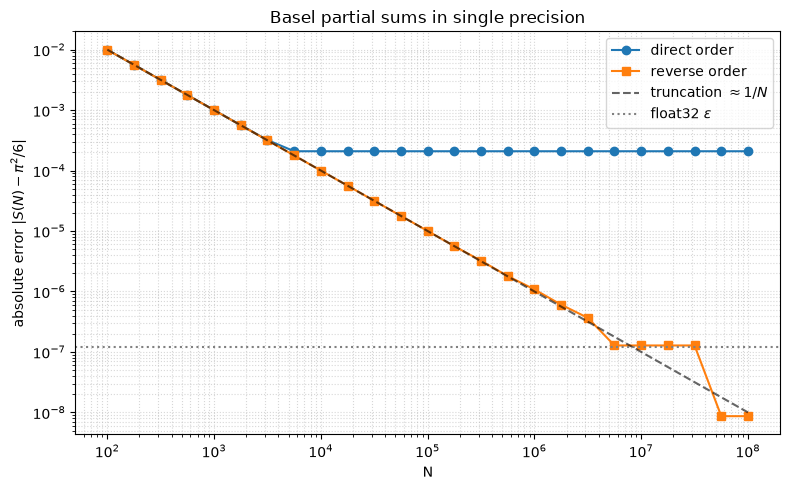

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(Ns, record["direct"], "o-", label="direct order")
ax.loglog(Ns, record["reverse"], "s-", label="reverse order")
ax.loglog(Ns, 1.0 / Ns, "k--", alpha=0.6, label=r"truncation $\approx 1/N$")
ax.axhline(EPS32, color="0.5", linestyle=":", label=r"float32 $\varepsilon$")

ax.set_xlabel("N")
ax.set_ylabel(r"absolute error $|S(N) - \pi^2/6|$")
ax.set_title("Basel partial sums in single precision")
ax.grid(True, which="both", linestyle=":", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

### Reading the plot

- For small $N$ both orders coincide: **truncation** dominates and the error follows $1/N$.
- The **direct** curve flattens early (around $N \approx 5\times10^3$): once $1/n^2 < \varepsilon\,S \approx 2\times10^{-7}$, i.e. $n \gtrsim 2200$, new terms no longer change the running sum. Adding more terms cannot improve it.
- The **reverse** curve keeps improving because the smallest terms are added while the running sum is still small, so their relative precision is preserved. It approaches the single-precision floor $\sim \varepsilon$ (and can even dip below, since the absolute error is small near the exact value).
- The exercise answer: direct and reverse sums **disagree** for large $N$; reverse is closer to $\pi^2/6$.

### Reproducing in C and C++

Same algorithm, scalar loop, with an explicit order and an error computed in `double`:

```c
/* basel.c: compile with gcc -O2 -Wall -Wextra -o basel basel.c -lm */
#include <stdio.h>
#include <stdlib.h>
#include <math.h>

int main(int argc, char **argv)
{
    long N = (argc > 1) ? atol(argv[1]) : 1000000;
    int reverse = (argc > 2);           /* any 2nd arg -> reverse order */
    float sum = 0.0f;

    if (reverse) {
        for (long n = N; n >= 1; --n) sum += 1.0f / ((float)n * (float)n);
    } else {
        for (long n = 1; n <= N; ++n) sum += 1.0f / ((float)n * (float)n);
    }

    double exact = M_PI * M_PI / 6.0;
    printf("N=%ld order=%s sum=%.9f abs_error=%.6e\n",
           N, reverse ? "reverse" : "direct", (double)sum, fabs((double)sum - exact));
    return 0;
}
```

State the compiler and options in the report. Avoid `-ffast-math` / `-Ofast`: they let the compiler reassociate the sum and defeat the point of the comparison. With such options the scalar loop may also be auto-vectorized, which changes both speed and accuracy.

## Exercise 2 — Parallel Hello, World!

A **shared-memory** run uses threads in one process (OpenMP, `OMP_NUM_THREADS`). A **distributed-memory** run uses separate MPI processes / ranks (`mpiexec`, `srun`). The **hybrid** run is $P$ ranks $\times$ $T$ threads and must print $P \times T$ lines.

### Python `threading` demo (shared-memory hierarchy)

Python threads reproduce the thread hierarchy, but the GIL means ordinary Python does not use several cores. The thread count is controlled here directly, the way `OMP_NUM_THREADS` does for OpenMP.

In [6]:
import threading
import socket

host = socket.gethostname()
T = 4  # like OMP_NUM_THREADS=4
lines = []
lock = threading.Lock()


def worker(tid):
    with lock:
        lines.append(f"thread={tid:2d} of {T:2d} on {host}")


threads = [threading.Thread(target=worker, args=(i,)) for i in range(T)]
for th in threads:
    th.start()
for th in threads:
    th.join()

print(f"{len(lines)} lines (expected {T}), order not part of the result:")
print("\n".join(lines))

4 lines (expected 4), order not part of the result:
thread= 0 of  4 on MacBook-Pro-di-Francesco.local
thread= 1 of  4 on MacBook-Pro-di-Francesco.local
thread= 2 of  4 on MacBook-Pro-di-Francesco.local
thread= 3 of  4 on MacBook-Pro-di-Francesco.local


### C — OpenMP shared memory

```c
/* hello_shared_world.c: gcc -fopenmp -O2 -o hello_shared_world hello_shared_world.c */
#include <stdio.h>
#include <unistd.h>
#include <omp.h>

int main(void)
{
    char host[256];
    gethostname(host, sizeof host);

#pragma omp parallel
    {
        int tid = omp_get_thread_num();
        int nth = omp_get_num_threads();
        printf("thread=%d of %d on %s\n", tid, nth, host);
    }
    return 0;
}
```

Run with `OMP_NUM_THREADS=4 ./hello_shared_world`: exactly one line per thread.

### C — hybrid MPI + OpenMP

Each MPI process creates its threads and reports rank, thread and node:

```c
/* hello_parallel_world.c: mpicc -fopenmp -O2 -o hello_parallel_world hello_parallel_world.c */
#include <stdio.h>
#include <unistd.h>
#include <mpi.h>
#include <omp.h>

int main(int argc, char **argv)
{
    MPI_Init(&argc, &argv);

    int rank, size;
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    MPI_Comm_size(MPI_COMM_WORLD, &size);

    char host[MPI_MAX_PROCESSOR_NAME];
    int hlen;
    MPI_Get_processor_name(host, &hlen);

#pragma omp parallel
    {
        int tid = omp_get_thread_num();
        int nth = omp_get_num_threads();
        printf("rank=%d/%d thread=%d/%d on %s\n", rank, size, tid, nth, host);
    }

    MPI_Finalize();
    return 0;
}
```

Launch: `mpiexec -n 4 ./hello_parallel_world` with `OMP_NUM_THREADS` set as desired. The program must print $P \times T$ lines.

### Python `mpi4py` sketch (optional)

If `mpi4py` is available (`mpiexec -n P python hello_parallel_world.py`):

```python
from mpi4py import MPI
import socket

comm = MPI.COMM_WORLD
rank, size = comm.rank, comm.size
host = socket.gethostname()
tid, nth = 0, 1  # set from your threading layer
print(f"rank={rank}/{size} thread={tid}/{nth} on {host}")
```

### Slurm batch templates

Load the same modules used to compile, then launch with `srun`. Three runs:

```bash
#!/usr/bin/env bash
#SBATCH --job-name=hello_omp
#SBATCH --partition=lab4
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=8
export OMP_NUM_THREADS=$SLURM_CPUS_PER_TASK
module use /srv/software/easybuild/hmns/x86-64-v2/modules/all/Core
module load GCC/13.2.0
srun ./hello_shared_world
```

```bash
#!/usr/bin/env bash
#SBATCH --job-name=hello_mpi
#SBATCH --partition=lab4
#SBATCH --nodes=2
#SBATCH --ntasks=8
#SBATCH --cpus-per-task=1
export OMP_NUM_THREADS=1
module use /srv/software/easybuild/hmns/x86-64-v2/modules/all/Core
module load GCC/13.2.0 OpenMPI/4.1.6
srun ./hello_parallel_world
```

```bash
#!/usr/bin/env bash
#SBATCH --job-name=hello_hybrid
#SBATCH --partition=lab4
#SBATCH --nodes=2
#SBATCH --ntasks=4
#SBATCH --cpus-per-task=4
export OMP_NUM_THREADS=$SLURM_CPUS_PER_TASK
module use /srv/software/easybuild/hmns/x86-64-v2/modules/all/Core
module load GCC/13.2.0 OpenMPI/4.1.6
srun ./hello_parallel_world
```

For each run, the number of lines, the ranks, the thread indices and the node names must match the Slurm request.

## Report reminders

- State the machine: on WILSON the partition, nodes, ranks, threads, allocation, modules; on a laptop the CPU model, OS and compiler.
- Report times with the problem and resource sizes; repeat short runs when the variability is comparable with the differences studied.
- Strong scaling: fixed problem, $S_p = T_1/T_p$, $E_p = S_p/p$. Weak scaling: roughly constant work per processing element, state how the problem grows.
- Use only short code excerpts in the report and provide the full source separately.

## OPTIONAL: SIMD intrinsics

Vectorize the Basel partial sum and compare with the scalar version in **speed and accuracy**. SIMD instructions and intrinsics are processor-specific: AVX on x86 (WILSON `lab4` nodes), NEON on ARM and Apple silicon. State the compiler options of the scalar version too: with `-ffast-math` a scalar loop can be vectorized or reordered by the compiler itself.

First, check which instruction sets this machine supports:

In [7]:
import platform
import socket
import subprocess

print(f"host     = {socket.gethostname()}")
print(f"machine  = {platform.machine()} ({platform.system()} {platform.release()})")

if platform.system() == "Darwin":   # macOS, Apple silicon (NEON)
    brand = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                           capture_output=True, text=True).stdout.strip()
    print("CPU:", brand)
else:                                # Linux (lscpu, as on WILSON)
    out = subprocess.run(["lscpu"], capture_output=True, text=True).stdout
    for line in out.splitlines():
        if line.lower().startswith("model name") or line.lower().startswith("flags"):
            print(line)

host     = MacBook-Pro-di-Francesco.local
machine  = arm64 (Darwin 27.0.0)
CPU: Apple M3 Pro


### AVX example (x86, WILSON)

```c
/* basel_avx.c: gcc -O2 -mavx -o basel_avx basel_avx.c -lm */
#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <immintrin.h>

int main(int argc, char **argv)
{
    long N = (argc > 1) ? atol(argv[1]) : 1000000L;
    long i = 1;
    __m256 one = _mm256_set1_ps(1.0f);
    __m256 acc = _mm256_setzero_ps();

    for (; i + 8 <= N; i += 8) {
        /* lanes 0..7 = n = i..i+7 */
        __m256 f = _mm256_set_ps((float)(i+7), (float)(i+6), (float)(i+5),
                                 (float)(i+4), (float)(i+3), (float)(i+2),
                                 (float)(i+1), (float)i);
        f = _mm256_mul_ps(f, f);
        acc = _mm256_add_ps(acc, _mm256_div_ps(one, f));
    }

    float tmp[8];
    _mm256_storeu_ps(tmp, acc);
    float sum = 0.0f;
    for (int k = 0; k < 8; ++k) sum += tmp[k];
    for (; i <= N; ++i) sum += 1.0f / ((float)i * (float)i);  /* tail */

    double exact = M_PI * M_PI / 6.0;
    printf("N=%ld simd sum=%.9f abs_error=%.6e\n",
           N, (double)sum, fabs((double)sum - exact));
    return 0;
}
```

### NEON example (ARM, Apple silicon)

```c
/* basel_neon.c: clang -O2 -o basel_neon basel_neon.c -lm */
#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <arm_neon.h>

int main(int argc, char **argv)
{
    long N = (argc > 1) ? atol(argv[1]) : 1000000L;
    long i = 1;
    float32x4_t one = vdupq_n_f32(1.0f);
    float32x4_t acc = vdupq_n_f32(0.0f);

    for (; i + 4 <= N; i += 4) {
        float32x4_t f = vdupq_n_f32((float)i);
        f = vsetq_lane_f32((float)(i+1), f, 1);
        f = vsetq_lane_f32((float)(i+2), f, 2);
        f = vsetq_lane_f32((float)(i+3), f, 3);
        f = vmulq_f32(f, f);
        acc = vaddq_f32(acc, vdivq_f32(one, f));
    }

    float tmp[4];
    vst1q_f32(tmp, acc);
    float sum = tmp[0] + tmp[1] + tmp[2] + tmp[3];
    for (; i <= N; ++i) sum += 1.0f / ((float)i * (float)i);  /* tail */

    double exact = M_PI * M_PI / 6.0;
    printf("N=%ld simd sum=%.9f abs_error=%.6e\n",
           N, (double)sum, fabs((double)sum - exact));
    return 0;
}
```

### How to compare with the scalar version

- Build the scalar `basel.c` (full code in the earlier section) and the SIMD version with the same `-O2`; record both in the report.
- On WILSON, run the timings **in a batch job on a compute node**, never on the login node. The `lab4` partition mixes processor generations; select the node type with the Slurm option `--constraint` and save the `lscpu` output of the node.
- Time with `time ./basel 100000000` (or `/usr/bin/time -l` on macOS) and repeat short runs when variability is comparable with the differences studied.
- Accuracy: the SIMD sum evaluates the same single-precision terms, so it should agree with the scalar result within rounding; under `-ffast-math` the compiler may reassociate the scalar loop and change the error. Intrinsics with an approximate reciprocal (`_mm256_rcp_ps`) trade accuracy for speed: document the loss if used.

### Report checklist for the optional part

- processor model and instruction set (`lscpu` on WILSON; `sysctl machdep.cpu.brand_string` on macOS);
- compiler options of both scalar and SIMD versions;
- elapsed times, repeatability, problem and resource sizes;
- accuracy comparison: does the SIMD sum agree with the scalar single-precision sum?